# From one manifold to another with a stochastic bridge

This notebook isolates the mathematical problem behind cat → dog and, eventually, human ↔ AI image transport. We observe independent samples from two laws $\mu_0$ and $\mu_1$; there are no paired examples. A frozen self-supervised encoder (DINO in the image experiment) supplies a semantic ground cost, entropic OT supplies a coupling, and score–flow matching amortizes a continuous stochastic path.

The 2-D example is deliberately small enough to see every object and execute on CPU. The same functions operate on flattened image latents.

## 1. The object is a law on paths

Let $\Omega=C([0,1],\mathbb R^d)$ and let $R^\varepsilon$ be Brownian reference measure with $dX_t=\sqrt{\varepsilon}dW_t$. The Schrödinger bridge is

$$P^\star=\arg\min_{P:\,P_0=\mu_0,\,P_1=\mu_1}\mathrm{KL}(P\|R^\varepsilon).$$

It disintegrates as $P^\star(d\omega)=\int R^\varepsilon_{xy}(d\omega)\,\pi^\star(dx,dy)$. Thus there are two separate decisions: an endpoint coupling $\pi^\star$, then a bridge conditional on each endpoint pair. Independent random pairing silently chooses $\mu_0\otimes\mu_1$ and discards instance correspondence.

In [1]:
import math
import matplotlib.pyplot as plt
import torch
from torch import nn

from brown_bridge.ot import sinkhorn, sinkhorn_divergence
from brown_bridge.paths import sample_coupling
from brown_bridge.stochastic_interpolants import (
    brownian_interpolant,
    make_stochastic_interpolant_batch,
    sliced_wasserstein_squared,
    nelson_drifts,
)

torch.manual_seed(7)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})

## 2. Two unpaired empirical manifolds

The visible coordinates stand in for image latents. The hidden angle features stand in for domain-suppressed DINO descriptors: they retain pose/instance content while ignoring which manifold rendered it. The endpoint samples are shuffled independently, so array indices carry no pairing information.

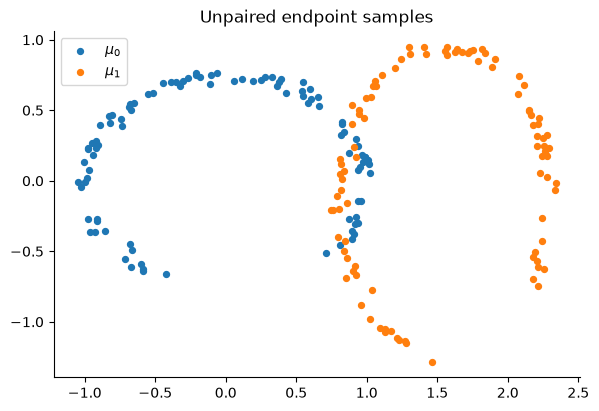

In [2]:
n = 96
theta0 = torch.rand(n) * 1.65 * math.pi - 0.3 * math.pi
theta1 = torch.rand(n) * 1.65 * math.pi - 0.3 * math.pi
source = torch.stack((torch.cos(theta0), 0.75 * torch.sin(theta0)), 1)
target = torch.stack((1.55 + 0.75 * torch.cos(theta1 + 0.35), -0.15 + 1.1 * torch.sin(theta1 + 0.35)), 1)
source += 0.035 * torch.randn_like(source)
target += 0.035 * torch.randn_like(target)
source_content = torch.stack((torch.cos(theta0), torch.sin(theta0)), 1)
target_content = torch.stack((torch.cos(theta1), torch.sin(theta1)), 1)

fig, ax = plt.subplots()
ax.scatter(*source.T, s=18, label=r"$\mu_0$")
ax.scatter(*target.T, s=18, label=r"$\mu_1$")
ax.set(aspect="equal", title="Unpaired endpoint samples")
ax.legend();

## 3. Semantic entropic OT chooses plausible counterparts

For empirical weights $a,b$ and semantic cost $C_{ij}$, solve

$$\min_{\pi\mathbf 1=a,\,\pi^\top\mathbf 1=b}\langle\pi,C\rangle+\tau\,\mathrm{KL}(\pi\|a\otimes b).$$

The entropy parameter controls whether one source has a nearly deterministic counterpart or a distribution of plausible targets. It is distinct from the path diffusion $\varepsilon$.

converged=True, iterations=610, max marginal error=8.94e-08


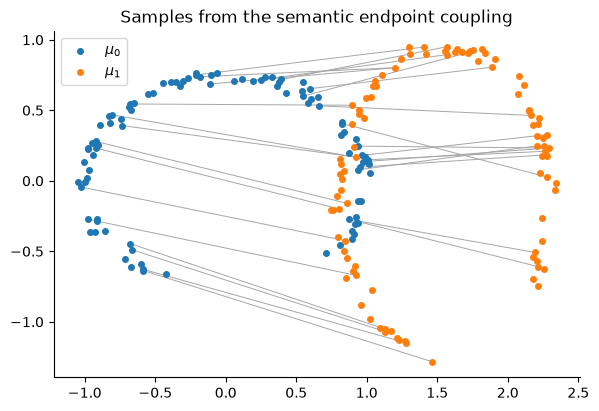

In [3]:
ot = sinkhorn(source_content, target_content, epsilon=0.04, cost="angular_squared")
print(f"converged={ot.converged}, iterations={ot.iterations}, "
      f"max marginal error={max(ot.row_marginal_error, ot.column_marginal_error):.2e}")

pairs = sample_coupling(ot.plan, source, target, 28, generator=torch.Generator().manual_seed(11))
fig, ax = plt.subplots()
for x, y in zip(pairs.source, pairs.target):
    ax.plot([x[0], y[0]], [x[1], y[1]], color="0.65", lw=0.7, zorder=0)
ax.scatter(*source.T, s=16, label=r"$\mu_0$")
ax.scatter(*target.T, s=16, label=r"$\mu_1$")
ax.set(aspect="equal", title="Samples from the semantic endpoint coupling")
ax.legend();

## 4. A simulation-free Brownian interpolant

For $(X_0,X_1)\sim\pi$, $Z\sim N(0,I)$, and $\gamma(t)=\sqrt{\varepsilon t(1-t)}$, define

$$I_t=(1-t)X_0+tX_1+\gamma(t)Z.$$

The endpoints are exact. At interior times, the pathwise targets are

$$\dot I_t=X_1-X_0+\frac{\varepsilon(1-2t)}{2\gamma(t)}Z,\qquad \nabla_x\log p(I_t\mid X_0,X_1)=-\frac{Z}{\gamma(t)}.$$

Least-squares regression conditions these targets on $I_t=x$, giving current velocity $v_t(x)$ and marginal score $s_t(x)=\nabla\log\rho_t(x)$. No learned SDE is simulated to create a training batch.

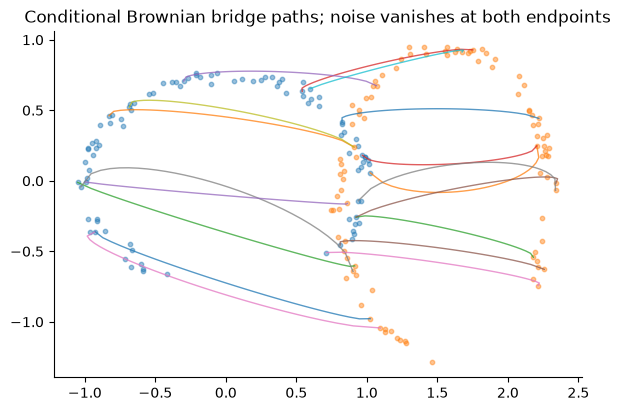

In [4]:
times = torch.linspace(0, 1, 31)
pairs = sample_coupling(ot.plan, source, target, 18, generator=torch.Generator().manual_seed(19))
noise = torch.randn_like(pairs.source, generator=torch.Generator().manual_seed(23))
path = torch.stack([brownian_interpolant(pairs.source, pairs.target, t, noise, epsilon=0.08) for t in times])

fig, ax = plt.subplots()
for trajectory in path.transpose(0, 1):
    ax.plot(*trajectory.T, lw=1.0, alpha=0.75)
ax.scatter(*source.T, s=10, alpha=0.45)
ax.scatter(*target.T, s=10, alpha=0.45)
ax.set(aspect="equal", title="Conditional Brownian bridge paths; noise vanishes at both endpoints");

## 5. Amortize the path into velocity and score fields

A single small network predicts both fields. In images this MLP becomes a latent U-Net or compact DiT; the objective and coupling sampler do not change. The score term is downweighted here because its unweighted conditional variance grows near the endpoints.

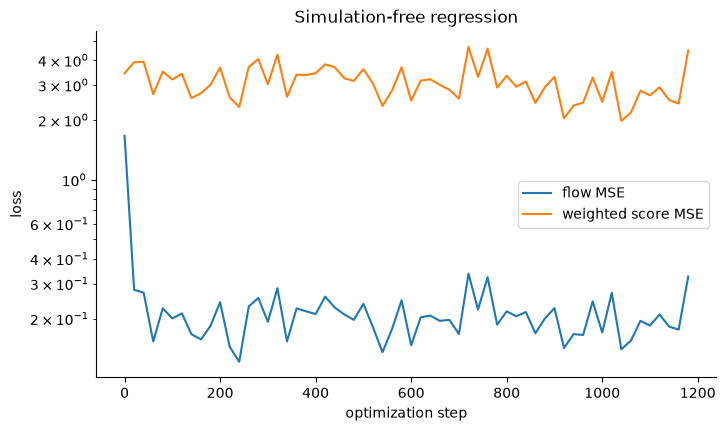

In [5]:
class VelocityScore(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, 96), nn.SiLU(), nn.Linear(96, 96), nn.SiLU(), nn.Linear(96, 4))

    def forward(self, x, t):
        prediction = self.net(torch.cat((x, t[:, None]), 1))
        return prediction[:, :2], prediction[:, 2:]

model = VelocityScore()
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-5)
generator = torch.Generator().manual_seed(31)
history = []
for step in range(1200):
    batch = make_stochastic_interpolant_batch(ot.plan, source, target, 256, epsilon=0.08, minimum_time=0.01, endpoint_bias=0.35, generator=generator)
    velocity, score = model(batch.state, batch.time)
    flow_loss = (velocity - batch.velocity_target).square().mean()
    score_loss = (score - batch.score_target).square().mean()
    loss = flow_loss + 0.02 * score_loss
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    if step % 20 == 0:
        history.append((step, flow_loss.item(), score_loss.item()))

fig, ax = plt.subplots()
steps, flow_losses, score_losses = map(torch.tensor, zip(*history))
ax.plot(steps, flow_losses, label="flow MSE")
ax.plot(steps, 0.02 * score_losses, label="weighted score MSE")
ax.set(xlabel="optimization step", ylabel="loss", yscale="log", title="Simulation-free regression")
ax.legend();

## 6. Coerce the learned flow to satisfy both endpoint laws

The interpolant has exact endpoints, but a finite neural regression and a numerical solver do not inherit that property automatically. We therefore add a short, differentiable full-interval rollout and penalize both terminal marginals:

$$\mathcal L_{\mathrm{end}}=\mathrm{SW}_2^2((\Phi_\theta^{0\to1})_\#\mu_0,\mu_1)+\mathrm{SW}_2^2((\Phi_\theta^{1\to0})_\#\mu_1,\mu_0).$$

This is a small fine-tuning phase, not a replacement for simulation-free score–flow matching. The reverse term prevents a one-sided correction from damaging the reciprocal map. Sliced Wasserstein solves exact one-dimensional OT problems along fixed random projections, avoiding an RBF bandwidth. For image latents, a debiased minibatch Sinkhorn divergence is the stronger replacement when memory permits.

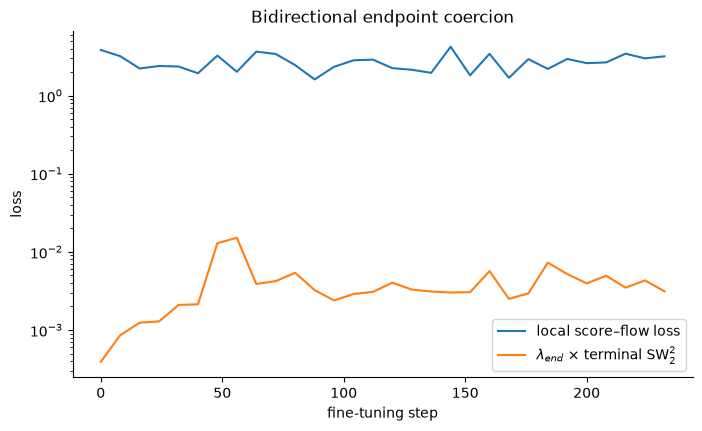

In [6]:
def probability_flow_rollout(initial, *, reverse=False, steps=12):
    x = initial
    start = 1.0 if reverse else 0.0
    dt = (-1.0 if reverse else 1.0) / steps
    for k in range(steps):
        physical_time = start + k * dt
        t = torch.full((len(x),), physical_time).clamp(0.01, 0.99)
        velocity, _ = model(x, t)
        proposal = x + dt * velocity
        t_next = torch.full((len(x),), physical_time + dt).clamp(0.01, 0.99)
        next_velocity, _ = model(proposal, t_next)
        x = x + 0.5 * dt * (velocity + next_velocity)
    return x

with torch.no_grad():
    baseline_ode_endpoint = probability_flow_rollout(source[::2], steps=80).clone()

terminal_directions = torch.randn(64, source.shape[1], generator=generator)
terminal_history = []
for step in range(240):
    batch = make_stochastic_interpolant_batch(ot.plan, source, target, 128, epsilon=0.08, minimum_time=0.01, endpoint_bias=0.35, generator=generator)
    velocity, score = model(batch.state, batch.time)
    local_loss = (velocity - batch.velocity_target).square().mean() + 0.02 * (score - batch.score_target).square().mean()
    forward_end = probability_flow_rollout(source, steps=12)
    backward_end = probability_flow_rollout(target, reverse=True, steps=12)
    endpoint_loss = sliced_wasserstein_squared(forward_end, target, directions=terminal_directions) + sliced_wasserstein_squared(backward_end, source, directions=terminal_directions)
    lambda_endpoint = 0.05 + 0.95 * step / 239
    loss = local_loss + lambda_endpoint * endpoint_loss
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    if step % 8 == 0:
        terminal_history.append((step, local_loss.item(), endpoint_loss.item(), lambda_endpoint))

fig, ax = plt.subplots()
fine_steps, local_losses, endpoint_losses, endpoint_weights = map(torch.tensor, zip(*terminal_history))
ax.plot(fine_steps, local_losses, label="local score–flow loss")
ax.plot(fine_steps, endpoint_weights * endpoint_losses, label=r"$\lambda_{end}$ × terminal $\mathrm{SW}_2^2$")
ax.set(xlabel="fine-tuning step", ylabel="loss", yscale="log", title="Bidirectional endpoint coercion")
ax.legend();

## 7. One density path, several dynamics

The continuity equation is $\partial_t\rho_t+\nabla\cdot(\rho_t v_t)=0$. For diffusion rate $\alpha_t$, Nelson's forward/backward drifts are

$$b_t^+=v_t+\tfrac12\alpha_t s_t,\qquad b_t^-=v_t-\tfrac12\alpha_t s_t,$$

so $b_t^+-b_t^-=\alpha_t\nabla\log\rho_t$. The probability-flow ODE $dX_t=v_tdt$ and Itô SDE $dX_t=b_t^+dt+\sqrt{\alpha_t}dW_t$ have the same one-time marginals when the fields are exact, but different individual trajectories. Use the ODE for one stable morph and the SDE to expose conditional diversity.

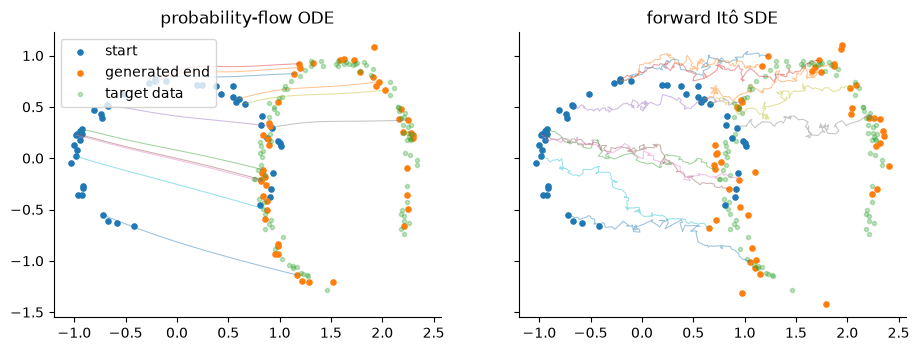

In [7]:
@torch.no_grad()
def integrate(initial, *, stochastic, steps=100, seed=41):
    x = initial.clone()
    trajectory = [x.clone()]
    dt = 1.0 / steps
    rng = torch.Generator().manual_seed(seed)
    for k in range(steps):
        physical_time = k * dt
        t = torch.full((len(x),), physical_time).clamp(0.01, 0.99)
        velocity, score = model(x, t)
        if stochastic:
            diffusion_rate = 0.08 * 4.0 * physical_time * (1.0 - physical_time)
            drift, _ = nelson_drifts(velocity, score, diffusion_rate=diffusion_rate)
            x = x + dt * drift + math.sqrt(diffusion_rate * dt) * torch.randn(x.shape, generator=rng)
        else:
            midpoint = x + 0.5 * dt * velocity
            mid_time = torch.full((len(x),), physical_time + 0.5 * dt).clamp(0.01, 0.99)
            mid_velocity, _ = model(midpoint, mid_time)
            x = x + dt * mid_velocity
        trajectory.append(x.clone())
    return torch.stack(trajectory)

initial = source[::2]
ode_path = integrate(initial, stochastic=False)
sde_path = integrate(initial, stochastic=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, learned_path, title in zip(axes, (ode_path, sde_path), ("probability-flow ODE", "forward Itô SDE")):
    for trajectory in learned_path[:, ::4].transpose(0, 1):
        ax.plot(*trajectory.T, lw=0.75, alpha=0.45)
    ax.scatter(*initial.T, s=14, label="start")
    ax.scatter(*learned_path[-1].T, s=14, label="generated end")
    ax.scatter(*target.T, s=9, alpha=0.3, label="target data")
    ax.set(aspect="equal", title=title)
axes[0].legend(loc="upper left");

In [8]:
before, _ = sinkhorn_divergence(initial, target, epsilon=0.12, cost="sqeuclidean", max_iterations=300)
baseline, _ = sinkhorn_divergence(baseline_ode_endpoint, target, epsilon=0.12, cost="sqeuclidean", max_iterations=300)
after_ode, _ = sinkhorn_divergence(ode_path[-1], target, epsilon=0.12, cost="sqeuclidean", max_iterations=300)
after_sde, _ = sinkhorn_divergence(sde_path[-1], target, epsilon=0.12, cost="sqeuclidean", max_iterations=300)
print({"before": round(before.item(), 4), "regression only": round(baseline.item(), 4), "coerced ODE": round(after_ode.item(), 4), "SDE endpoint": round(after_sde.item(), 4)})

{'before': 2.846, 'regression only': 0.0745, 'coerced ODE': 0.0531, 'SDE endpoint': 0.0464}


## 8. Translation to cat ↔ dog and human ↔ AI

1. Encode images with a frozen diffusion VAE, retaining a spatial latent tensor.
2. Compute the endpoint coupling from DINO content descriptors with the domain direction projected out.
3. Train one direction-conditioned latent network for $v_t$ and $s_t$. Add two primary regularizers: time-reversal consistency and pathwise content preservation.
4. Decode a uniform physical-time grid. Report endpoint distribution metrics *and* k-NN manifold-tube distance over time.
5. Sample held-out sources uniformly, then sample their counterparts from the held-out coupling. Independently random pairs are a stress test, not the main conditional demo.

IFM is a useful second stage: use generated trajectories to correct the coupling/path where it leaves data-supported regions, then refit. It is not a replacement for the two-marginal stochastic formulation.

### Reading

- Léonard, *A Survey of the Schrödinger Problem and Some of Its Connections with Optimal Transport* (2014).
- Albergo, Boffi & Vanden-Eijnden, *Stochastic Interpolants* (2023/2026 revision).
- Tong et al., *Simulation-Free Schrödinger Bridges via Score and Flow Matching* (AISTATS 2024).
- De Bortoli et al., *Schrödinger Bridge Flow for Unpaired Data Translation* (NeurIPS 2024).
- Zhang, Cheng & Ver Steeg, *Exploring the Design Space of Diffusion Bridge Models* (NeurIPS 2025).
- Liu et al., *Unpaired Image-to-Image Translation via a Self-Supervised Semantic Bridge* (2026).